# Boiling Point vs Humidity Correlation Experiment

This notebook demonstrates the Humidity-Driven Nucleation hypothesis test using the Clausius-Clapeyron equation to calculate theoretical boiling points. It analyzes synthetic data to check the correlation between boiling point error and relative humidity.

In [1]:
# Install dependencies
import sys
if 'google.colab' in sys.modules:
    %pip install -q numpy pandas scipy matplotlib loguru
else:
    import subprocess
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "numpy", "pandas", "scipy", "matplotlib", "loguru"])

In [2]:
import numpy as np
import pandas as pd
from scipy.stats import pearsonr, spearmanr
import json
import matplotlib.pyplot as plt

# Colour each series by its ROLE from COLOURS
COLOURS = {
    "method": "#0173B2",  # the paper's own method, model or condition
    "baseline": "#949494",  # the main baseline, control or reference
    "other_1": "#DE8F05",  
    "other_2": "#029E73",  
    "other_3": "#CC78BC",  
    "other_4": "#CA9161",  
    "other_5": "#56B4E9",  
}
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["CMU Serif", "Computer Modern Roman", "DejaVu Serif"],
    "mathtext.fontset": "cm",
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.grid.axis": "y",
    "grid.color": "#CCCCCC",
    "grid.alpha": 0.6,
    "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=list(COLOURS.values())),
    "image.cmap": "cividis",
    "legend.frameon": False,
    "figure.constrained_layout.use": True,
    "figure.dpi": 120,
})

Matplotlib is building the font cache; this may take a moment.


In [3]:
import http.client
import json
import urllib.request
from pathlib import Path

GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-daa948-boiling-point-prediction-error-as/main/round-1/experiment-2/demo/mini_demo_data.json"

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data_json = load_data()
data = pd.DataFrame(data_json)

GitHub data unavailable, using local mini_demo_data.json: HTTP Error 404: Not Found


In [5]:
# Config
N_SAMPLES = 50  # Using the 50 points from mini_demo_data.json

### Correlation Analysis
Calculating Pearson and Spearman correlation between T_err and Relative_Humidity.

In [6]:
pearson_r, _ = pearsonr(data['T_err'], data['Relative_Humidity'])
spearman_r, _ = spearmanr(data['T_err'], data['Relative_Humidity'])

print(f"Pearson Correlation: {pearson_r:.4f}")
print(f"Spearman Correlation: {spearman_r:.4f}")

Pearson Correlation: 0.9642
Spearman Correlation: 0.9460


findfont: Failed to find font weight normal for CMU Serif, now using 500.


findfont: Failed to find font weight normal for CMU Serif, now using 500.


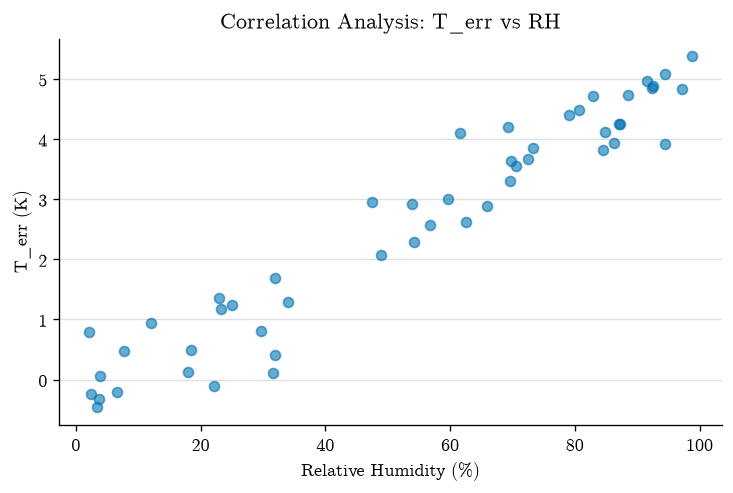

In [7]:
plt.figure(figsize=(6, 4))
plt.scatter(data['Relative_Humidity'], data['T_err'], color=COLOURS['method'], alpha=0.6)
plt.xlabel('Relative Humidity (%)')
plt.ylabel('T_err (K)')
plt.title('Correlation Analysis: T_err vs RH')
plt.show()